# Smart Gas AI — Exploratory Data Analysis

This notebook inspects the supplied **synthetic/enclosed** MQ-5 dataset, verifies the
session-grouped split, and reviews the frozen classifier's held-out results.

The deployed model consumes only `mq5_adc`. Temperature and humidity are retained
for context but are **not** model inputs.

> **Safety note:** this is an educational prototype on synthetic data. It is not a
> certified gas detector and must not be used for leak, fire or explosion alarms.


## 1. Setup

Run this notebook from the repository root or from the `notebooks/` directory.
The next cell locates the project root and imports the shared configuration.


In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src").is_dir():
    raise RuntimeError(
        "Run this notebook from the repository root or the notebooks/ directory."
    )
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src import config, utils

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)

print(f"Repository root: {ROOT.name}")
print(
    f"pandas {pd.__version__} | numpy {np.__version__} | "
    f"seaborn {sns.__version__}"
)

Repository root: smart-gas-ai-release
pandas 3.0.6 | numpy 2.5.3 | seaborn 0.13.2


## 2. Load and verify the raw dataset

The raw CSV is treated as immutable. Its SHA-256 checksum is pinned in
`src/config.py`; the pipeline aborts if the file changes.


In [2]:
df = pd.read_csv(config.DATASET_PATH)
actual_hash = utils.sha256_file(config.DATASET_PATH)

print(f"Rows x columns: {df.shape[0]:,} x {df.shape[1]}")
print(f"SHA-256: {actual_hash}")
print(f"Checksum matches config: {actual_hash == config.EXPECTED_DATASET_SHA256}")
print()
print(df.head(8).to_string(index=False))

Rows x columns: 3,564 x 5
SHA-256: 82BFC7557E247D06E54C7B81AD5F2A9A294C5A44FD006274D451C6D99F1F01C7
Checksum matches config: True

session_id  mq5_adc  temperature_c  humidity_rh_pct   label
    ENC_01      967           27.7             95.0  Normal
    ENC_01      972           27.9             95.0  Normal
    ENC_01     1221           29.1             91.4  Normal
    ENC_01     2241           25.9             83.3 Warning
    ENC_01     2142           27.4             87.8 Warning
    ENC_01      864           26.5             92.5  Normal
    ENC_01     3189           27.6             91.2  Danger
    ENC_01      906           28.8             80.5  Normal


### Data-quality checks

The dataset has no missing cells, no duplicate rows and no duplicate feature rows.
Each session contributes the same number of rows per class.


In [3]:
quality = pd.DataFrame(
    {
        "check": [
            "missing cells",
            "exact duplicate rows",
            "duplicate feature rows",
            "sessions",
            "labels",
        ],
        "value": [
            int(df.isna().sum().sum()),
            int(df.duplicated().sum()),
            int(df.duplicated(subset=config.FEATURE_COLUMNS_ALL).sum()),
            int(df[config.SESSION_COLUMN].nunique()),
            int(df[config.TARGET_COLUMN].nunique()),
        ],
    }
)
print(quality.to_string(index=False))
print()
print(
    df[config.TARGET_COLUMN]
    .value_counts()
    .rename_axis("label")
    .to_frame("rows")
    .to_string()
)

                 check  value
         missing cells      0
  exact duplicate rows      0
duplicate feature rows      0
              sessions     18
                labels      3

         rows
label        
Normal   1188
Warning  1188
Danger   1188


## 3. Feature overview

`mq5_adc` is the only model feature. Temperature and humidity vary independently
of the class in this synthetic dataset; they are useful context, not predictors.


In [4]:
summary = df[config.FEATURE_COLUMNS_ALL].describe().T
summary["range"] = summary["max"] - summary["min"]
print(summary.round(2).to_string())

                  count     mean     std    min      25%     50%     75%     max   range
mq5_adc          3564.0  1793.84  778.02  197.0  1044.75  1758.0  2481.0  3602.0  3405.0
temperature_c    3564.0    27.50    6.28   15.0    23.40    26.4    31.1    44.7    29.7
humidity_rh_pct  3564.0    54.48   18.48   15.0    39.70    51.1    69.4    95.0    80.0


### Class balance and ADC separation

The three classes are exactly balanced. The ADC distributions overlap at the
Normal/Warning and Warning/Danger boundaries, which is where the classifier makes
almost all of its errors.


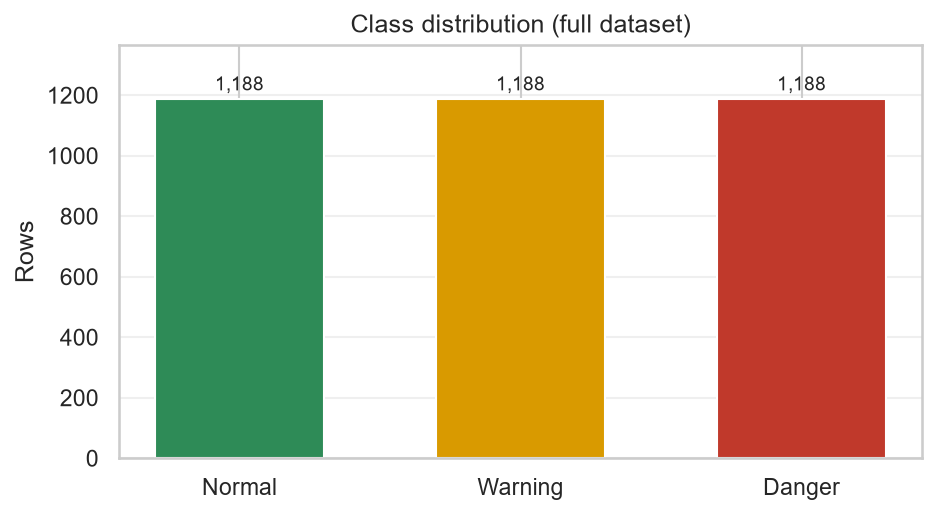

In [5]:
order = config.CLASS_ORDER
counts = df[config.TARGET_COLUMN].value_counts().reindex(order)

fig, ax = plt.subplots(figsize=(6.4, 3.6))
bars = ax.bar(
    counts.index,
    counts.values,
    color=[config.CLASS_COLORS[name] for name in order],
    width=0.6,
)
for bar, value in zip(bars, counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 15,
        f"{value:,}",
        ha="center",
        va="bottom",
        fontsize=9,
    )
ax.set_ylim(0, counts.max() * 1.15)
ax.set_ylabel("Rows")
ax.set_title("Class distribution (full dataset)")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

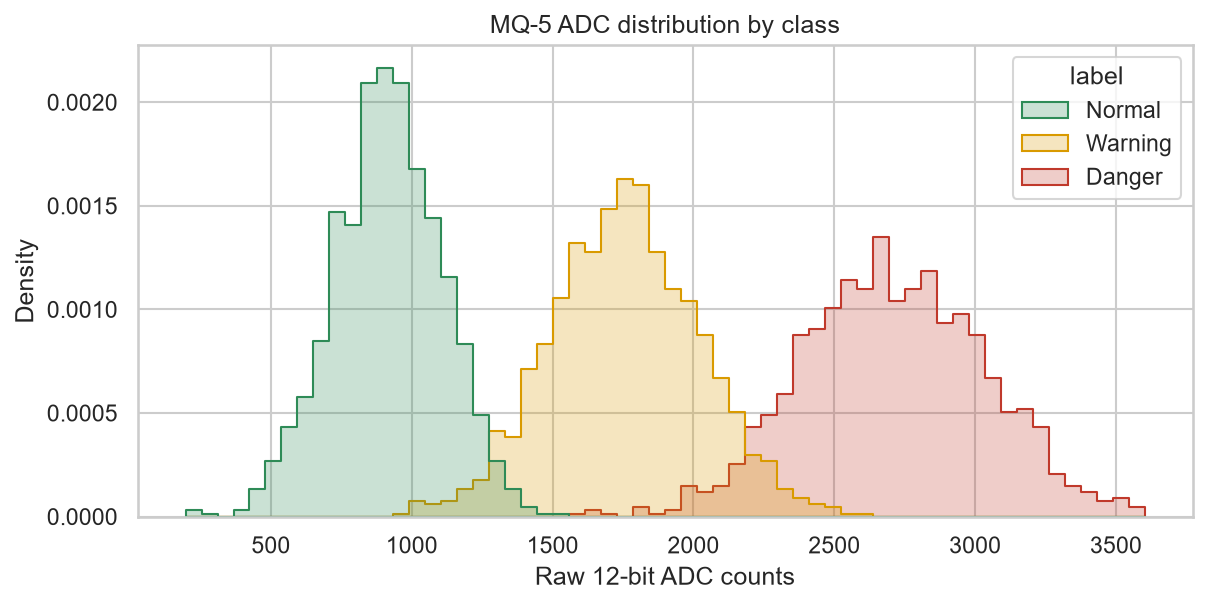

In [6]:
fig, ax = plt.subplots(figsize=(8.2, 4.2))
sns.histplot(
    data=df,
    x="mq5_adc",
    hue="label",
    hue_order=order,
    bins=60,
    element="step",
    stat="density",
    common_norm=False,
    palette=config.CLASS_COLORS,
    ax=ax,
)
ax.set_title("MQ-5 ADC distribution by class")
ax.set_xlabel("Raw 12-bit ADC counts")
ax.set_ylabel("Density")
plt.tight_layout()
plt.show()

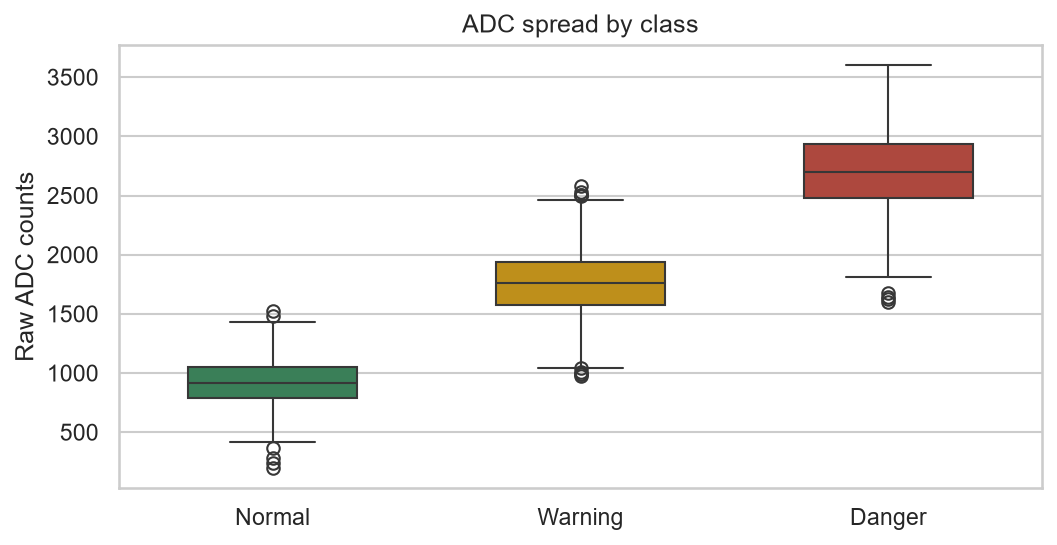

In [7]:
fig, ax = plt.subplots(figsize=(7.2, 3.8))
sns.boxplot(
    data=df,
    x="label",
    y="mq5_adc",
    order=order,
    hue="label",
    palette=config.CLASS_COLORS,
    legend=False,
    width=0.55,
    ax=ax,
)
ax.set_title("ADC spread by class")
ax.set_xlabel("")
ax.set_ylabel("Raw ADC counts")
plt.tight_layout()
plt.show()

## 4. Context features and session effects

The synthetic generator varies temperature and humidity, but class membership is
driven by the ADC level. The table below shows that the context means are similar
across classes.


In [8]:
context = (
    df.groupby(config.TARGET_COLUMN)[config.FEATURE_COLUMNS_ALL]
    .mean()
    .reindex(order)
)
print("Mean values by class:")
print(context.round(2).to_string())
print()
print("Feature correlation matrix:")
print(df[config.FEATURE_COLUMNS_ALL].corr().round(3).to_string())

Mean values by class:
         mq5_adc  temperature_c  humidity_rh_pct
label                                           
Normal    916.14          27.54            54.82
Warning  1757.86          27.52            54.38
Danger   2707.52          27.46            54.23

Feature correlation matrix:
                 mq5_adc  temperature_c  humidity_rh_pct
mq5_adc            1.000          0.008            0.001
temperature_c      0.008          1.000           -0.036
humidity_rh_pct    0.001         -0.036            1.000


### Session-to-session variation

Whole sessions are held out, so it is useful to check whether class ADC levels
are stable across the 18 sessions.


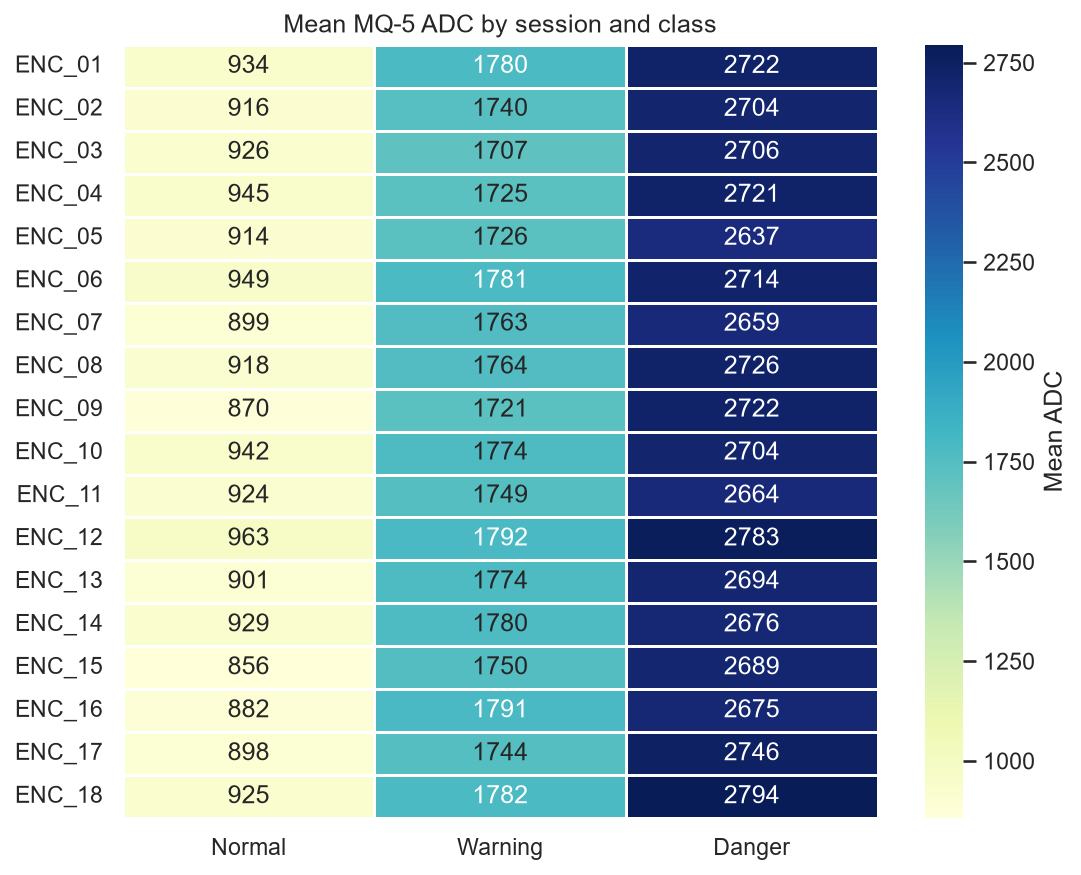

In [9]:
session_means = (
    df.groupby([config.SESSION_COLUMN, config.TARGET_COLUMN])["mq5_adc"]
    .mean()
    .unstack()
    .reindex(columns=order)
)

fig, ax = plt.subplots(figsize=(7.4, 6.0))
sns.heatmap(
    session_means,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label": "Mean ADC"},
    ax=ax,
)
ax.set_title("Mean MQ-5 ADC by session and class")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

## 5. Session-grouped split

The split is fixed by seed 42: 12 training sessions, 3 validation sessions and
3 test sessions. No session appears in more than one partition.


In [10]:
splits = {
    name: pd.read_csv(config.PROCESSED_DIR / f"{name}.csv")
    for name in ("train", "validation", "test")
}

rows = []
for name, part in splits.items():
    counts = part[config.TARGET_COLUMN].value_counts().reindex(order)
    rows.append(
        {
            "split": name,
            "rows": len(part),
            "sessions": part[config.SESSION_COLUMN].nunique(),
            **{label: int(counts[label]) for label in order},
        }
    )
print(pd.DataFrame(rows).to_string(index=False))
print()

session_sets = {
    name: set(part[config.SESSION_COLUMN]) for name, part in splits.items()
}
print(
    "Session overlap:",
    {
        f"{a} & {b}": sorted(session_sets[a] & session_sets[b])
        for a, b in (
            ("train", "validation"),
            ("train", "test"),
            ("validation", "test"),
        )
    },
)
print("Test sessions:", sorted(session_sets["test"]))
assert not (
    session_sets["train"] & session_sets["validation"]
    or session_sets["train"] & session_sets["test"]
    or session_sets["validation"] & session_sets["test"]
)

     split  rows  sessions  Normal  Warning  Danger
     train  2376        12     792      792     792
validation   594         3     198      198     198
      test   594         3     198      198     198

Session overlap: {'train & validation': [], 'train & test': [], 'validation & test': []}
Test sessions: ['ENC_01', 'ENC_02', 'ENC_09']


## 6. Frozen model results

The final model is `gaussian_nb_adc`: a `StandardScaler` followed by
`GaussianNB`, using `mq5_adc` only. It was selected by leave-one-session-out CV
on the training sessions; the test set was not used for selection.


In [11]:
metrics = utils.read_json(config.METRICS_DIR / "metrics.json")

summary_rows = [
    (
        "Training CV macro F1",
        metrics["cv"]["reported_selection_score"]["mean_macro_f1"],
    ),
    ("Validation macro F1", metrics["validation"]["macro_f1"]),
    ("Test accuracy", metrics["test"]["accuracy"]),
    ("Test macro F1", metrics["test"]["macro_f1"]),
    (
        "Test Danger recall",
        metrics["test"]["per_class"]["Danger"]["recall"],
    ),
    ("Test errors (of 594)", metrics["test"]["n_errors"]),
]
print(pd.DataFrame(summary_rows, columns=["metric", "value"]).to_string(index=False))

              metric     value
Training CV macro F1  0.949764
 Validation macro F1  0.951200
       Test accuracy  0.939394
       Test macro F1  0.939253
  Test Danger recall  0.949495
Test errors (of 594) 36.000000


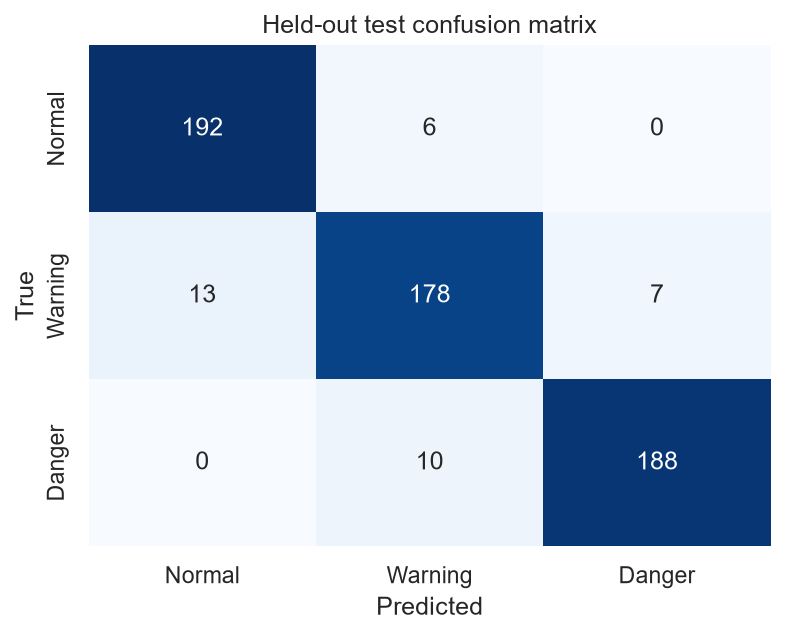

In [12]:
matrix = np.asarray(metrics["test"]["confusion_matrix"])

fig, ax = plt.subplots(figsize=(5.4, 4.4))
sns.heatmap(
    matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=order,
    yticklabels=order,
    ax=ax,
)
ax.set_title("Held-out test confusion matrix")
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
plt.tight_layout()
plt.show()

In [13]:
per_class = pd.DataFrame(metrics["test"]["per_class"]).T.reindex(order)
print("Test per-class metrics:")
print(per_class.round(4).to_string())
print()

session_table = pd.read_csv(
    config.METRICS_DIR / "per_session_test_metrics.csv"
)
print("Per-session test results:")
print(session_table.round(4).to_string(index=False))

Test per-class metrics:
         precision  recall      f1  support
Normal      0.9366  0.9697  0.9529    198.0
Warning     0.9175  0.8990  0.9082    198.0
Danger      0.9641  0.9495  0.9567    198.0

Per-session test results:
session_id   n  accuracy  macro_f1  danger_recall  warning_recall  normal_recall  errors  danger_to_normal
    ENC_01 198    0.9343    0.9342         0.9394          0.8939         0.9697      13                 0
    ENC_02 198    0.9192    0.9192         0.9091          0.8788         0.9697      16                 0
    ENC_09 198    0.9646    0.9645         1.0000          0.9242         0.9697       7                 0


### Model parameters exported to firmware

The GaussianNB parameters are small enough to embed directly in the ESP32
firmware. `models/gas_model.json` and `firmware/esp32_gas_detection/gas_model.h`
are generated from this fitted pipeline.


In [14]:
import joblib

model = joblib.load(config.MODELS_DIR / "final_model.joblib")
scaler = model.named_steps["scaler"]
nb = model.named_steps["model"]

print(f"StandardScaler mean  = {scaler.mean_[0]:.4f}")
print(f"StandardScaler scale = {scaler.scale_[0]:.4f}")
print()
parameters = pd.DataFrame(
    {
        "theta": nb.theta_.ravel(),
        "variance": nb.var_.ravel(),
        "prior": nb.class_prior_,
    },
    index=nb.classes_,
).reindex(order)
print(parameters.round(5).to_string())

StandardScaler mean  = 1794.6434
StandardScaler scale = 776.3957

           theta  variance    prior
Normal  -1.12913   0.05896  0.33333
Warning -0.04450   0.11253  0.33333
Danger   1.17363   0.17420  0.33333


## 7. Rule-based baseline

A two-threshold rule was fitted on the training split only. It is a useful sanity
check: if a simple ADC cut-point performs just as well, the ML model's extra
complexity is not justified by this dataset.


In [15]:
baseline = metrics["baseline"]
thresholds = baseline["thresholds"]
print(
    "Training-split thresholds: "
    f"Normal <= {thresholds['normal_max']:.0f}, "
    f"Warning <= {thresholds['warning_max']:.0f}, otherwise Danger"
)
print()

comparison_rows = [
    (
        "Rule baseline (validation)",
        baseline["validation"]["accuracy"],
        baseline["validation"]["macro_f1"],
    ),
    (
        "Rule baseline (test)",
        baseline["test"]["accuracy"],
        baseline["test"]["macro_f1"],
    ),
    ("GaussianNB (test)", metrics["test"]["accuracy"], metrics["test"]["macro_f1"]),
]
print(
    pd.DataFrame(
        comparison_rows,
        columns=["system / split", "accuracy", "macro_f1"],
    )
    .round(4)
    .to_string(index=False)
)
print()

mcnemar = baseline["mcnemar_test_vs_rule"]
print(
    "McNemar exact test: "
    f"model-only correct={mcnemar['model_only_correct']}, "
    f"baseline-only correct={mcnemar['baseline_only_correct']}, "
    f"p={mcnemar['exact_binomial_p']:.4f}"
)

Training-split thresholds: Normal <= 1300, Warning <= 2200, otherwise Danger

            system / split  accuracy  macro_f1
Rule baseline (validation)    0.9512    0.9512
      Rule baseline (test)    0.9411    0.9409
         GaussianNB (test)    0.9394    0.9393

McNemar exact test: model-only correct=0, baseline-only correct=1, p=1.0000


## 8. Probability curve

The classifier's probabilities transition smoothly between classes. The Warning
band is the narrowest, which matches its lower recall.


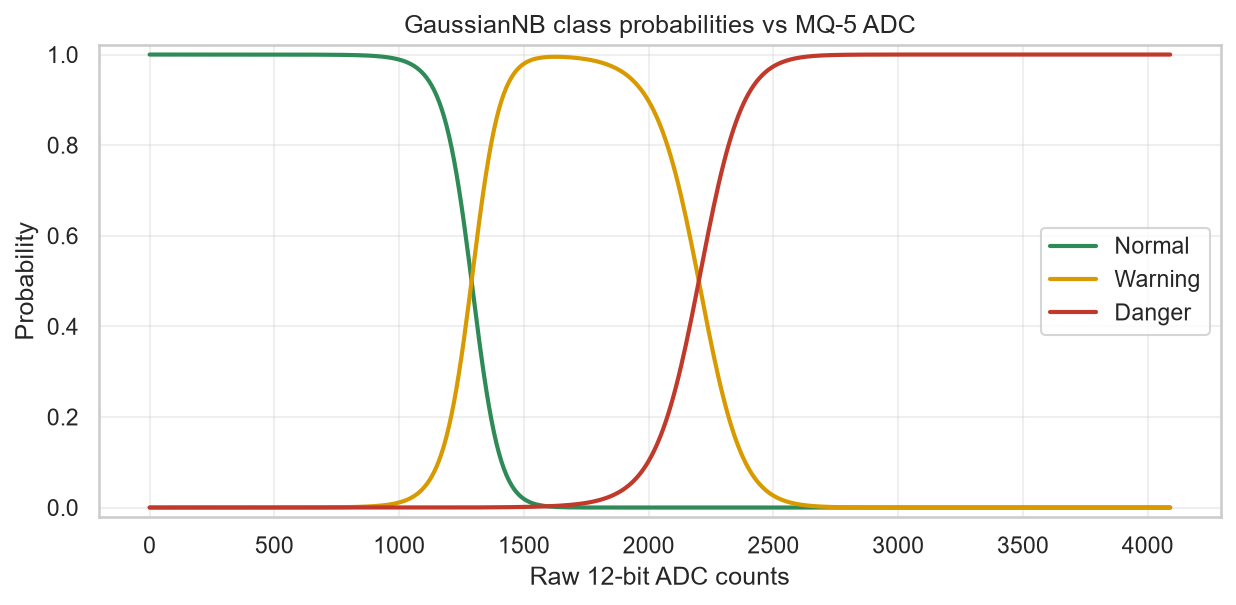

In [16]:
adc_grid = np.arange(0, 4096, 10, dtype=float)
probabilities = model.predict_proba(pd.DataFrame({"mq5_adc": adc_grid}))
model_classes = list(nb.classes_)
reorder = [model_classes.index(name) for name in order]
probabilities = probabilities[:, reorder]

fig, ax = plt.subplots(figsize=(8.4, 4.2))
for index, name in enumerate(order):
    ax.plot(
        adc_grid,
        probabilities[:, index],
        label=name,
        color=config.CLASS_COLORS[name],
        linewidth=2,
    )
ax.set_title("GaussianNB class probabilities vs MQ-5 ADC")
ax.set_xlabel("Raw 12-bit ADC counts")
ax.set_ylabel("Probability")
ax.set_ylim(-0.02, 1.02)
ax.legend(loc="center right")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Takeaways

- The dataset has **3,564 rows**, **18 sessions**, exactly **1,188 rows per class**,
  no missing values and no duplicates.
- The split is session-grouped: 12 train / 3 validation / 3 test sessions, with no
  overlap. The test sessions are `ENC_01`, `ENC_02` and `ENC_09`.
- The frozen model is **GaussianNB on `mq5_adc` only**. Temperature and humidity
  are context features in the dataset, not model inputs.
- Held-out test performance: **93.94% accuracy**, **93.93% macro F1**, **94.95%
  Danger recall**, and **0 Danger → Normal** errors.
- The two-threshold rule reaches **94.11% accuracy / 94.09% macro F1** on the same
  test split. McNemar's exact test gives **p = 1.0**, so this notebook does not
  claim a significant advantage for the ML model.
- All results describe synthetic data. Real MQ-5 sensors add warm-up drift, noise,
  humidity sensitivity and unit-to-unit variation that this dataset does not
  contain.

See `docs/limitations.md` and `models/model_card.json` for the deployment caveats.
